In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install Keras-Preprocessing

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.6/42.6 kB 2.0 MB/s eta 0:00:00


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import re,json,nltk
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
import numpy as np
from keras.preprocessing.text import Tokenizer
from keras_preprocessing.sequence import pad_sequences
from keras.models import Sequential
from keras.layers import LSTM,Dense,Embedding,SpatialDropout1D
from keras.utils.np_utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import  confusion_matrix
import seaborn
from sklearn.feature_extraction.text import CountVectorizer
import plotly as py
import cufflinks as cf
import tensorflow
from tensorflow.keras import Sequential
from plotly.offline import iplot
py.offline.init_notebook_mode(connected=True)
cf.go_offline()
from tensorflow.keras.layers import LSTM,Dense,Dropout,Activation,Embedding,Flatten,Bidirectional,MaxPooling2D, Conv1D, MaxPooling1D
from keras.layers import MaxPool1D
from tensorflow.keras.optimizers import SGD,Adam
from tensorflow.keras import regularizers

class color: # Text style
   PURPLE = '\033[95m'
   CYAN = '\033[96m'
   DARKCYAN = '\033[36m'
   BLUE = '\033[94m'
   GREEN = '\033[92m'
   YELLOW = '\033[93m'
   RED = '\033[91m'
   BOLD = '\033[1m'
   UNDERLINE = '\033[4m'
   END = '\033[0m'
# Warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [4]:


from sklearn import metrics
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.python.keras.models import Sequential

from keras.layers import MaxPool1D

from tensorflow.keras.optimizers import SGD,Adam
from tensorflow.keras import regularizers

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical


import h5py
import csv
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_recall_fscore_support
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report


from nltk.corpus import stopwords
import nltk
import re
from nltk.stem import WordNetLemmatizer
import string
from nltk.tokenize import word_tokenize
from nltk.util import ngrams

In [5]:
file_path = '/content/drive/MyDrive/Bkash Fraud paper/Bkash Fraud Analysis.csv'

In [6]:
df = pd.read_csv(file_path,encoding='UTF-16',sep='\t')
df.head(3)

,Comments,Label
0,জব এর কথা বলে আমার থেকে ১২০০ টাকা নিয়েছে। ৫০০ ...,Fraud
1,বৃত্তির কথা বলে আমার থেকে আজকে ৩৫০০০ হাজার টাক...,Fraud
2,ভাই আমার পরিচিতো এক জন মহিলা বিকাশ ভেরিফাই কোট...,Fraud


In [7]:
s_word =pd.read_excel('/content/drive/MyDrive/code file/stopwords_bangla.xlsx')
stop = s_word['words'].tolist()

In [8]:
display(s_word)

,Unnamed: 0,words
0,0,অই
1,1,অগত্যা
2,2,অত: পর
3,3,অতএব
4,4,অথচ
...,...,...
727,727,হয়েই
728,728,হয়েছিল
729,729,হয়েছে
730,730,হয়েছেন


In [9]:
def process_conversations(Conversation):
    stp = open('/content/drive/MyDrive/code file/stopword-bn.txt','r',encoding="utf8").read().split()
    result = Conversation.split()
    Conversation = [word.strip() for word in result if word not in stp ]
    Conversation =" ".join(Conversation)
    Conversation = re.sub('[^\u0980-\u09FF]',' ',str(Conversation))
    return Conversation

In [10]:
import re
def process_comments(Comments):
    Comments = re.sub('[^\u0980-\u09FF]',' ',str(Comments)) #removing unnecessary punctuation
    return Comments

In [11]:
# Apply the function into the dataframe
df['cleaned'] = df['Comments'].apply(process_comments)

# print some cleaned reviews from the dataset
sample_data = [16,17,26]
for i in sample_data:
     print('Original:\n',df.Comments[i],'\nCleaned:\n',
           df.cleaned[i],'\n','Label:-- ',df.Label[i],'\n')

Original:
 আমি বিকাশে ২৪০০০ টাকা প্রতারিত হয়েছি কিন্তু জেনে আমারও প্রতারিত হয়েছি ওই নাম্বারে ফোন দেওয়ার ফলে বলছে যে টাকা নাকি উঠিয়ে নিয়ে গেছে দুজন লোক এখন কি করবো 
Cleaned:
 আমি বিকাশে ২৪০০০ টাকা প্রতারিত হয়েছি কিন্তু জেনে আমারও প্রতারিত হয়েছি ওই নাম্বারে ফোন দেওয়ার ফলে বলছে যে টাকা নাকি উঠিয়ে নিয়ে গেছে দুজন লোক এখন কি করবো 
 Label:--  Fraud 

Original:
 আমার আব্বুর বিকাশ থেকে গতকাল রাতে ৪০০০ হাজার একশত ৬০ টাকা নিয়েছে 
Cleaned:
 আমার আব্বুর বিকাশ থেকে গতকাল রাতে ৪০০০ হাজার একশত ৬০ টাকা নিয়েছে 
 Label:--  Fraud 

Original:
 আমার সাথে আজ প্রতারণা হয়েছে আমার ১৪০৬৫ টাকা নিয়েছে 
Cleaned:
 আমার সাথে আজ প্রতারণা হয়েছে আমার ১৪০৬৫ টাকা নিয়েছে 
 Label:--  Fraud 



In [12]:
### Removing Small Texts

df['length'] = df['cleaned'].apply(lambda x:len(x.split()))

dataset = df.loc[df.length>3]
dataset = dataset.reset_index(drop = True)
print("After Cleaning:","\nRemoved {} Small conversations".format(len(df)-len(dataset)),
      "\nTotal conversations:",len(dataset))

dataset['no_char'] = df['cleaned'].apply(lambda cleaned: len(cleaned))

After Cleaning: 
Removed 0 Small conversations 
Total conversations: 520


**Stemming**

In [13]:
!pip install bangla-stemmer
from bangla_stemmer.stemmer import stemmer
## stemmer function
def stem_text (x):
  stmr = stemmer.BanglaStemmer()
  words=x.split(' ')
  stm = stmr.stem(words)
  words=(' ').join(stm)
  return words

In [14]:
df['stemming']=df['cleaned'].apply(stem_text)

Streaming output truncated to the last 5000 lines.
applied second rules..
applied second rules..
applied first rules..
applied first rules..
applied fourth rules..
applied first rules..
applied fourth rules..
applied second rules..
applied first rules..
applied fourth rules..
applied fourth rules..
applied second rules..
applied second rules..
applied fourth rules..
applied fourth rules..
applied second rules..
applied first rules..
applied fourth rules..
applied first rules..
applied second rules..
applied first rules..
applied second rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied third rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied second rules..
applied fourth rules..
applied fourth rules..
applied first rules..
applied fourth rules..
applied first rules..
applied fourth rules..
applied fourth rules..
applied second rules..
applied fourth rules..
applied first ru

In [15]:
df.head(3)

,Comments,Label,cleaned,length,stemming
0,জব এর কথা বলে আমার থেকে ১২০০ টাকা নিয়েছে। ৫০০ ...,Fraud,জব এর কথা বলে আমার থেকে ১২০০ টাকা নিয়েছে ৫০০ ...,19,জব এর কথা বলে আম থেক ১২০০ টাকা নিয় ৫০০ টাকা ই...
1,বৃত্তির কথা বলে আমার থেকে আজকে ৩৫০০০ হাজার টাক...,Fraud,বৃত্তির কথা বলে আমার থেকে আজকে ৩৫০০০ হাজার টাক...,16,বৃত্তির কথা বলে আম থেক আজ ৩৫০০০ হাজা টাকা নিয়ে...
2,ভাই আমার পরিচিতো এক জন মহিলা বিকাশ ভেরিফাই কোট...,Fraud,ভাই আমার পরিচিতো এক জন মহিলা বিকাশ ভেরিফাই কোট...,25,ভাই আম পরিচি এক জন মহিলা বিকাশ ভেরিফা কোট টি ব...


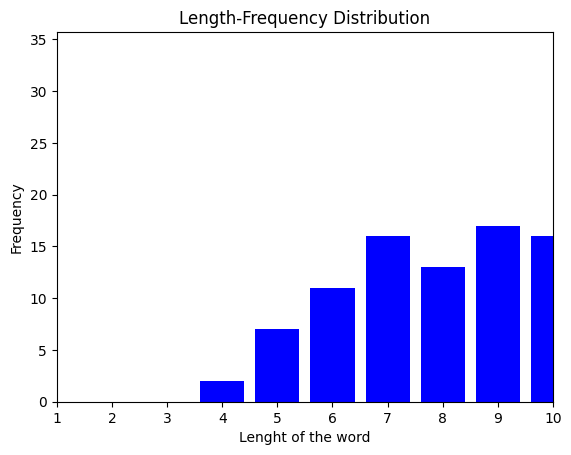

Maximum Length of a comment: 123
Minimum Length of a comment: 4
Average Length of a comment: 21.0


In [16]:
frequency = dict()
for i in dataset.length:
    frequency[i] = frequency.get(i, 0)+1

plt.bar(frequency.keys(), frequency.values(), color ="blue")
plt.xlim(1, 10)

plt.xlabel('Lenght of the word')
plt.ylabel('Frequency')
plt.title('Length-Frequency Distribution')
plt.show()
print(f"Maximum Length of a comment: {max(dataset.length)}")
print(f"Minimum Length of a comment: {min(dataset.length)}")
print(f"Average Length of a comment: {round(np.mean(dataset.length),0)}")

In [17]:
# data summary

def data_summary(df):
    reviews = []
    words = []
    u_words = []
    total_u_words = [word.strip().lower() for t in list(df.cleaned) for word in t.strip().split()]
    class_label= [k for k,v in df.Label.value_counts().to_dict().items()]
  # find word list
    for label in class_label:
        word_list = [word.strip().lower() for t in list(df[df.Label==label].cleaned) for word in t.strip().split()]
        counts = dict()
        for word in word_list:
                counts[word] = counts.get(word, 0)+1
        # sort the dictionary of word list
        ordered = sorted(counts.items(), key= lambda item: item[1],reverse = True)
        # reviewss per class
        reviews.append(len(list(df[df.Label==label].cleaned)))
        # Total Word per class
        words.append(len(word_list))
        # Unique words per class
        u_words.append(len(np.unique(word_list)))

        print("\nClass Name : ",label)
        print("Number of Comments:{}".format(len(list(df[df.Label==label].cleaned))))
        print("Number of Words:{}".format(len(word_list)))
        print("Number of Unique Words:{}".format(len(np.unique(word_list))))
        print("Most Frequent Words:\n")
        for k,v in ordered[:10]:
              print("{}\t{}".format(k,v))
    print("Total Number of Unique Words:{}".format(len(np.unique(total_u_words))))

    return reviews,words,u_words,class_label

#call the fucntion
reviews,words,u_words,class_names = data_summary(df)


Class Name :  Fraud
Number of Comments:260
Number of Words:5529
Number of Unique Words:1186
Most Frequent Words:

আমার	325
টাকা	321
থেকে	151
বিকাশ	123
নিয়ে	109
গেছে	101
করে	91
বলে	85
এর	81
আমি	79

Class Name :  Partial Fraud
Number of Comments:260
Number of Words:5624
Number of Unique Words:1222
Most Frequent Words:

আমার	306
টাকা	284
আমি	149
থেকে	134
করে	102
বিকাশ	97
গেছে	91
ভাই	79
হাজার	78
নিয়ে	75
Total Number of Unique Words:1807


In [18]:
data_matrix = pd.DataFrame({'Total comments':reviews,
                            'Total Words':words,
                            'Unique Words':u_words,
                            'Class Names':class_names})
data = pd.melt(data_matrix, id_vars="Class Names", var_name="Category", value_name="Values")

In [19]:
data

,Class Names,Category,Values
0,Fraud,Total comments,260
1,Partial Fraud,Total comments,260
2,Fraud,Total Words,5529
3,Partial Fraud,Total Words,5624
4,Fraud,Unique Words,1186
5,Partial Fraud,Unique Words,1222


# Label Encoding Function

In [20]:
def label_encoding(df,bool):
  '''
  This function will convert categorical class names into a numeric label
  '''
  le = LabelEncoder()
  le.fit(df.Label)
  encoded_labels = le.transform(df.Label)
  labels = np.array(encoded_labels) # Converting into numpy array
  class_names =le.classes_ ## Define the class names again
  if bool == True:
    print(color.BOLD+"\n\t\t\t===== Label Encoding ====="+color.END,"\nClass Names:-->",le.classes_)
  return labels

# Dataset Splitting Function

In [21]:
def dataset_split(news,Label):

  X,X_test,y,y_test = train_test_split(news,Label,train_size = 0.9,
                                                  test_size = 0.1,random_state =0)
  X_train,X_valid,y_train,y_valid = train_test_split(X,y,train_size = 0.8,
                                                  test_size = 0.2,random_state =0)
  print(color.BOLD+"Feature Size :======>"+color.END,X_train.shape[1])
  print(color.BOLD+"\nDataset Distribution:\n"+color.END)
  print("\tSet Name","\t\tSize")
  print("\t========\t\t======")

  print("\tFull\t\t\t",news.shape[0],
        "\n\tTraining\t\t",X_train.shape[0],
        "\n\tTest\t\t\t",X_test.shape[0],
        "\n\tValidation\t\t",X_valid.shape[0])

  return X_train,X_valid,X_test,y_train,y_valid,y_test

In [22]:
#df.cleaned = df.stemming.apply(lambda x:x.replace('\n',' '))

In [23]:
#df.head(3)

In [24]:
df.drop(["Comments", "length"], axis = 1, inplace=True)

In [25]:
df.head(3)

,Label,cleaned,stemming
0,Fraud,জব এর কথা বলে আমার থেকে ১২০০ টাকা নিয়েছে ৫০০ ...,জব এর কথা বলে আম থেক ১২০০ টাকা নিয় ৫০০ টাকা ই...
1,Fraud,বৃত্তির কথা বলে আমার থেকে আজকে ৩৫০০০ হাজার টাক...,বৃত্তির কথা বলে আম থেক আজ ৩৫০০০ হাজা টাকা নিয়ে...
2,Fraud,ভাই আমার পরিচিতো এক জন মহিলা বিকাশ ভেরিফাই কোট...,ভাই আম পরিচি এক জন মহিলা বিকাশ ভেরিফা কোট টি ব...


In [26]:
import re,nltk,json, pickle
def encoded_texts(dataset,padding_length,max_words):

  '''
  This function will encoded the text into a sequence of numbers
  '''

  tokenizer = Tokenizer(num_words = max_words, filters='!"#$%&()*+,-./:;<=>?@[\]^_`{|}~\t\n-',
                      split=' ', char_level=False, oov_token='', document_count=0)



 # Fit the tokenizer
  tokenizer.fit_on_texts(df.cleaned)
  #============================== Tokenizer Info =================================
  (word_counts,word_docs,word_index,document_count) = (tokenizer.word_counts,
                                                       tokenizer.word_docs,
                                                       tokenizer.word_index,
                                                       tokenizer.document_count)
  def tokenizer_info(mylist,bool):
    ordered = sorted(mylist.items(), key= lambda item: item[1],reverse = bool)
    for w,c in ordered[:10]:
      print(w,"\t",c)
  #=============================== Print all the information =========================
  print(color.BOLD+"\t\t\t====== Tokenizer Info ======"+color.END)
  print("Words --> Counts:")
  tokenizer_info(word_counts,bool =True )
  print("\nWords --> Documents:")
  tokenizer_info(word_docs,bool =True )
  print("\nWords --> Index:")
  tokenizer_info(word_index,bool =True )
  print("\nTotal Documents -->",document_count)

  #=========================== Convert string into list of integer indices =================
  sequences = tokenizer.texts_to_sequences(df.cleaned)
  word_index = tokenizer.word_index
  print(color.BOLD+"\n\t\t\t====== Encoded Sequences ======"+color.END,"\nFound {} unique tokens".format(len(word_index)))
  print(df.cleaned[10],"\n",sequences[10])

  #==================================== Pad Sequences ==============================
  corpus = keras.preprocessing.sequence.pad_sequences(sequences, value=0.0,
                                                      padding='post', maxlen= padding_length)
  print("\n\t\t\t====== Paded Sequences ======\n",df.cleaned[10],"\n",corpus[10])

  #=================================     Label Encoding ================================
  labels = label_encoding(df,True)

   # save the tokenizer into a pickle file
  with open(file_path+'tokenizer.pickle', 'wb') as handle:
    pickle.dump(tokenizer, handle, protocol=pickle.HIGHEST_PROTOCOL)

  return corpus,labels

#call the function
num_words = 5000
corpus,labels = encoded_texts(df,
                                300,num_words)
print("\nShape of Encoded Corpus =====>",corpus.shape)

			====== Tokenizer Info ======
Words --> Counts:
আমার 	 631
টাকা 	 605
থেকে 	 285
আমি 	 228
বিকাশ 	 220
করে 	 193
গেছে 	 192
নিয়ে 	 184
হাজার 	 149
ভাই 	 124

Words --> Documents:
টাকা 	 454
আমার 	 429
থেকে 	 251
গেছে 	 178
নিয়ে 	 172
বিকাশ 	 171
আমি 	 161
হাজার 	 148
করে 	 142
ভাই 	 106

Words --> Index:
দিয়েছিলাম 	 1808
বলছিলো 	 1807
একি 	 1806
অবিকল 	 1805
৪হাজার 	 1804
কোর্সের 	 1803
গ্রুপে 	 1802
১৪৫০০ 	 1801
পড়ে 	 1800
খপ্পরে 	 1799

Total Documents --> 520

			====== Encoded Sequences ====== 
Found 1808 unique tokens
আমার বিকাশ একাউন্ট  থেকে টাকা কেটে নিচ্ছে কিন্তু কেন নিচ্ছে আমি জানি না  
 [2, 6, 24, 4, 3, 190, 398, 44, 1029, 398, 5, 399, 17]

			====== Paded Sequences ======
 আমার বিকাশ একাউন্ট  থেকে টাকা কেটে নিচ্ছে কিন্তু কেন নিচ্ছে আমি জানি না  
 [   2    6   24    4    3  190  398   44 1029  398    5  399   17    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0 

# CNN Section

In [27]:
#Call Dataset Split Function
X_train,X_valid,X_test,y_train,y_valid,y_test = dataset_split(corpus,labels)

Feature Size :======> 300

Dataset Distribution:

	Set Name 		Size
	========		======
	Full			 520 
	Training		 374 
	Test			 52 
	Validation		 94


In [28]:
embedding_dimension = 128
input_length = 300
vocab_size = 5000
num_classes = 12
batch_size = 64
num_epochs = 100

accuracy_threshold = 0.97

In [29]:
###############################     CNN network architecture ################
model = tf.keras.models.Sequential([
tf.keras.layers.Embedding(vocab_size, embedding_dimension, input_length = input_length),
tf.keras.layers.Conv1D(128, 5, activation= 'relu'),
tf.keras.layers.MaxPool1D(pool_size=16),
tf.keras.layers.Dense(20,kernel_regularizer=regularizers.l2(0.01),activation="relu"),
keras.layers.Flatten(),
tf.keras.layers.Dense(num_classes , activation='softmax')])

model.summary()

model.compile(optimizer=keras.optimizers.Adam(),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])



Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 300, 128)          640000    
                                                                 
 conv1d (Conv1D)             (None, 296, 128)          82048     
                                                                 
 max_pooling1d (MaxPooling1D  (None, 18, 128)          0         
 )                                                               
                                                                 
 dense (Dense)               (None, 18, 20)            2580      
                                                                 
 flatten (Flatten)           (None, 360)               0         
                                                                 
 dense_1 (Dense)             (None, 12)                4332      
                                                        

In [30]:
history = model.fit(X_train,
    y_train,
    epochs=num_epochs,
    batch_size = batch_size,
    validation_data=(X_valid, y_valid),
    verbose =1)

Epoch 1/100
6/6 [==============================] - 3s 246ms/step - loss: 2.6898 - accuracy: 0.3663 - val_loss: 2.3808 - val_accuracy: 0.5638
Epoch 2/100
6/6 [==============================] - 1s 197ms/step - loss: 1.9934 - accuracy: 0.5401 - val_loss: 1.3719 - val_accuracy: 0.5745
Epoch 3/100
6/6 [==============================] - 1s 182ms/step - loss: 1.1309 - accuracy: 0.5775 - val_loss: 0.9984 - val_accuracy: 0.4362
Epoch 4/100
6/6 [==============================] - 1s 251ms/step - loss: 0.9667 - accuracy: 0.5214 - val_loss: 0.9517 - val_accuracy: 0.5638
Epoch 5/100
6/6 [==============================] - 2s 311ms/step - loss: 0.9433 - accuracy: 0.5160 - val_loss: 0.9458 - val_accuracy: 0.4574
Epoch 6/100
6/6 [==============================] - 2s 310ms/step - loss: 0.9190 - accuracy: 0.5321 - val_loss: 0.9564 - val_accuracy: 0.4255
Epoch 7/100
6/6 [==============================] - 2s 453ms/step - loss: 0.8859 - accuracy: 0.6176 - val_loss: 0.8940 - val_accuracy: 0.5638
Epoch 8/100
6

In [31]:
import tensorflow as tf

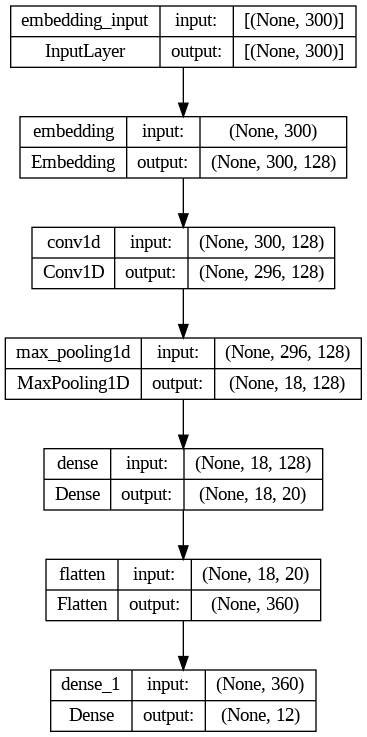

In [32]:
tf.keras.utils.plot_model(model, show_shapes=True)

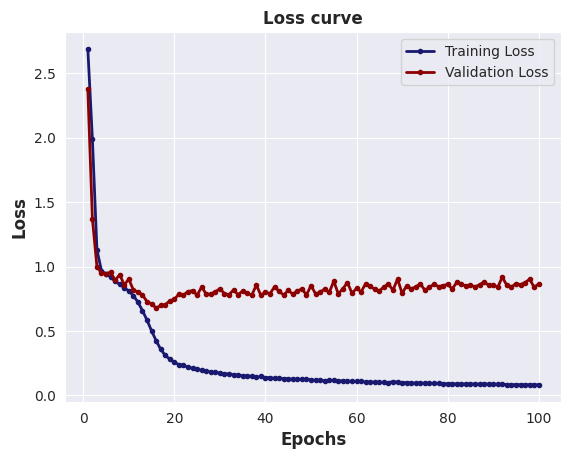

In [33]:
loss_values = history.history['loss']
val_loss_values = history.history['val_loss']
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs = range(1, len(acc) + 1)
sns.set_style('darkgrid')


plt.plot(epochs, loss_values, color='midnightblue', linewidth = 2,
          marker='o', markersize=3,label='Training Accuracy')
plt.plot(epochs, val_loss_values, color='darkred', linewidth = 2,
          marker='o', markersize=3,label='Training Accuracy')
plt.title('Loss curve',fontsize=12,fontweight='bold')
plt.xlabel('Epochs',fontsize=12,fontweight='bold')
plt.ylabel('Loss',fontsize=12,fontweight='bold')
plt.legend(['Training Loss','Validation Loss'])


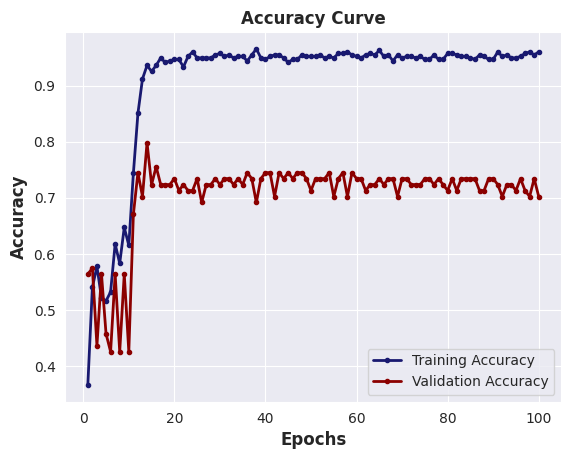

In [34]:
#=========================================================
                  ############### Epochs vs Validation Accuracy Plot ##########
                  #==========================================================


plt.plot(epochs, acc, color='midnightblue', linewidth = 2,
          marker='o', markersize=3,label='Training Accuracy')
plt.plot(epochs, val_acc, color='darkred', linewidth = 2,
          marker='o', markersize=3,label='Training Accuracy')
plt.title('Accuracy Curve',fontsize=12,fontweight='bold')
plt.xlabel('Epochs',fontsize=12,fontweight='bold')
plt.ylabel('Accuracy',fontsize=12,fontweight='bold')
plt.legend(['Training Accuracy','Validation Accuracy'])

In [35]:
class_names = ['Fraud', 'Partial Fraud']
predictions = model.predict(X_test)
y_pred = np.argmax(predictions, axis=1)
report = pd.DataFrame(classification_report(y_true = y_test, y_pred = y_pred, output_dict=True)).transpose()
report = report.rename(index={'0': 'Fraud','1':'Partial Fraud',})
report[['precision','recall','f1-score']]=report[['precision','recall','f1-score']].apply(lambda x: round(x*100,2))
report

2/2 [==============================] - 0s 25ms/step


,precision,recall,f1-score,support
Fraud,63.33,82.61,71.70,23.000000
Partial Fraud,81.82,62.07,70.59,29.000000
accuracy,71.15,71.15,71.15,0.711538
macro avg,72.58,72.34,71.14,52.000000
weighted avg,73.64,71.15,71.08,52.000000


2/2 [==============================] - 0s 21ms/step


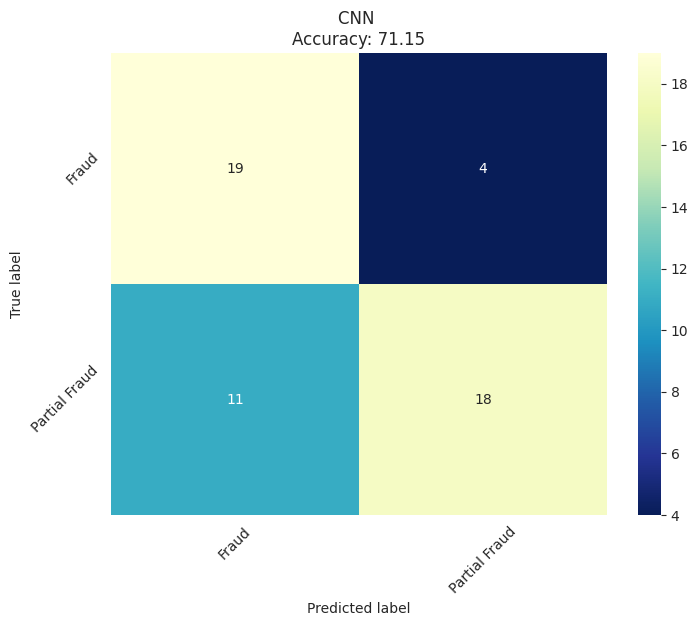

In [36]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score
predictions = model.predict(X_test)
y_pred = np.argmax(predictions, axis=1)

cm = confusion_matrix(y_test, y_pred)

class_names = ['Fraud', 'Partial Fraud']
# Transform to df for easier plotting
cm_df = pd.DataFrame(cm,index = class_names, columns = class_names)

plt.figure(figsize=(8,6))
sns.heatmap(cm_df, annot=True,cmap="YlGnBu_r", fmt='g')
plt.title('CNN \nAccuracy: {0:.2f}'.format(accuracy_score(y_test, y_pred)*100))
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.xticks(rotation = 45)
plt.yticks(rotation = 45)
plt.show()

In [37]:
import re,nltk,json, pickle
sample_comment = 'আমার স্বামীর বিকাশ একাউন্ট থেকে প্রতারকরা ভেরিফিকেশন নম্বরটা নিয়ে গেছে '
cleaned_comment = process_comments(sample_comment)

class_names = ['Fraud','Partial Fraud']

# load the saved tokenizer
with open(file_path+'tokenizer.pickle', 'rb') as handle:
    loaded_tokenizer = pickle.load(handle)
#print(len(loaded_tokenizer.word_index))
seq= loaded_tokenizer.texts_to_sequences([cleaned_comment])
padded = pad_sequences(seq, value=0.0,padding='post', maxlen= 300 )
pred = model.predict(padded)
#print(pred)
class_names[np.argmax(pred)]

1/1 [==============================] - 0s 30ms/step


'Fraud'